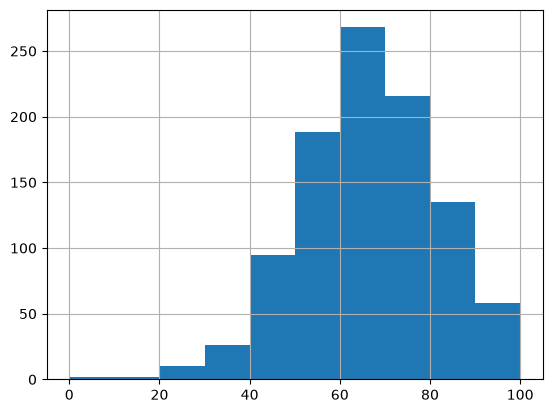

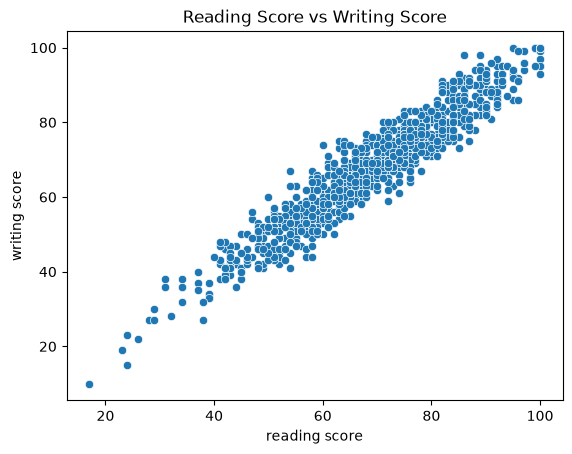

0.5642605403184358


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pickle
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

df = pd.read_csv("../data/StudentsPerformance.csv")

plt.figure()
df["math score"].hist()
plt.show()

plt.figure()
sns.scatterplot(data=df, x="reading score", y="writing score")
plt.title("Reading Score vs Writing Score")
plt.show()

X = df[["reading score", "writing score"]]
y = df["math score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
r2 = r2_score(y_test, predictions)

os.makedirs("../models", exist_ok=True)

with open("../models/student_model.pkl", "wb") as f:
    pickle.dump(model, f)

print(r2)